# Telecom Customer Churn Prediction & Retention Intelligence
*Classification - Explainable AI - Customer Risk Scoring - Retention Strategy*

## 1. Introduction

Customer churn - customers leaving for a competitor - is one of the costliest problems in telecom, because
acquiring a new subscriber is typically several times more expensive than retaining an existing one. This notebook builds an
end-to-end system that answers three questions:

* **WHO** is likely to churn? (classification + calibrated churn probability + risk level)
* **WHY** are they likely to churn? (SHAP explainability)
* **WHAT** should the company do about it? (rule-based retention layer + customer health score)

## 2. Problem Statement

> Build a classification-based machine learning model to predict whether a customer is likely to churn based on their
demographic details, usage patterns, billing information and service feedback.

## 3. Objectives

1. Generate a realistic dataset (20,000 customers, 37 predictors, ~30% churn).
2. Clean, impute and preprocess without data leakage (scikit-learn `Pipeline` + `ColumnTransformer`).
3. Explore the data and engineer behavioural-trend features.
4. Train and tune Logistic Regression, Random Forest and XGBoost; compare them with imbalance-aware metrics.
5. Output churn probability and LOW / MEDIUM / HIGH / CRITICAL risk, explain it with SHAP, and attach rule-based retention actions.

## 4. Dataset Description

The dataset is **synthetic** (seed 42) because no public dataset has all required feature groups. Churn is generated from a
latent logistic risk mechanism (contract, tenure, satisfaction, complaints, bill shock, network quality, usage decline ...) plus
unobserved noise, so the relationships are realistic but the problem is **not** perfectly separable. The latent risk is never saved.

| Group | Features |
|---|---|
| Demographics | age, gender, senior_citizen, city_tier |
| Account | tenure_months, contract_type, plan_type, number_of_lines, device_type |
| Usage | data_usage_gb, call_minutes, sms_count, international_minutes, roaming_usage, five_g_usage_percentage |
| Billing | monthly_charges, total_charges, average_bill_last_3_months, late_payment_count, payment_method |
| Network | network_drops, outage_minutes, average_download/upload_speed, call_drop_rate |
| Support | support_calls, complaints, average_resolution_time_hours, tickets_reopened |
| Feedback | satisfaction_score (1-10), nps_score (-100..100), negative_feedback_count |
| Behavioural change (3 months) | data_usage_change_3m, call_usage_change_3m, bill_change_3m, complaint_change_3m, satisfaction_change_3m |

## 5. Import Libraries

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200, "display.max_columns", 60)
sns.set_theme(style="whitegrid")
import preprocessing as prep, evaluate as ev, explain, retention, eda, generate_data
FIG = ROOT / "outputs" / "figures"; MET = ROOT / "outputs" / "metrics"
show = lambda name, w=800: display(Image(filename=str(FIG / name), width=w))

## 6. Data Generation / Loading

`generate_data.py` writes `data/telecom_churn.csv`. We generate it if it does not exist yet.

In [2]:
if not prep.DATA_PATH.exists():
    generate_data.main()
df = prep.load_data()
df.shape

(20000, 39)

## 7. Data Inspection

In [3]:
display(df.head())
display(df.dtypes.value_counts())
display(df.describe().T.round(2))

,customer_id,age,gender,senior_citizen,city_tier,tenure_months,contract_type,plan_type,number_of_lines,device_type,data_usage_gb,call_minutes,sms_count,international_minutes,roaming_usage,five_g_usage_percentage,data_usage_change_3m,call_usage_change_3m,monthly_charges,total_charges,average_bill_last_3_months,bill_change_3m,late_payment_count,payment_method,network_drops,outage_minutes,average_download_speed,average_upload_speed,call_drop_rate,support_calls,complaints,average_resolution_time_hours,tickets_reopened,complaint_change_3m,satisfaction_change_3m,satisfaction_score,nps_score,negative_feedback_count,churn
0,C100000,45,Male,0,3,17,Month-to-month,Standard,1,Android,9.11,321.0,95,0.0,0.0,27.2,-17.7,-4.8,550.10,9080.00,495.59,11.0,0,Credit Card,7,15.4,28.7,7.8,1.93,6,1,9.5,0,-2,0.7,4.0,-42.0,2,1
1,C100001,26,Female,0,2,39,Two year,Standard,3,Android,31.18,490.0,37,0.0,392.4,25.7,15.3,16.6,1155.56,45999.19,1063.07,8.7,0,Credit Card,1,261.9,41.9,5.0,1.53,0,1,33.5,1,-1,1.8,NaN,29.0,0,0
2,C100002,51,Male,0,1,41,Month-to-month,Premium,4,Feature Phone,15.71,382.0,90,NaN,0.0,0.0,-1.4,7.4,2565.94,100528.40,2416.14,6.2,0,Debit Card,3,14.3,43.3,7.9,0.83,3,1,5.7,0,1,-0.7,6.0,27.0,1,0
3,C100003,54,Female,0,1,72,Two year,Basic,1,iPhone,4.37,688.0,89,0.0,247.2,24.2,-29.7,-19.7,300.67,19686.80,318.51,-5.6,0,Credit Card,2,75.5,40.2,15.0,0.74,0,2,17.7,0,2,0.5,NaN,-38.0,0,0
4,C100004,18,Female,0,2,12,Month-to-month,Basic,1,Android,3.14,230.0,39,29.1,0.0,30.9,-15.9,-19.6,338.13,3668.50,299.23,13.0,1,Cash,1,90.9,57.9,18.8,1.76,1,0,4.7,0,0,1.3,7.0,85.0,1,0


float64    19
int64      14
str         6
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max
age,20000.0,40.89,13.40,18.00,31.00,40.00,50.00,85.00
senior_citizen,20000.0,0.09,0.29,0.00,0.00,0.00,0.00,1.00
city_tier,20000.0,2.00,0.78,1.00,1.00,2.00,3.00,3.00
tenure_months,20000.0,25.66,18.80,1.00,11.00,21.00,36.00,72.00
number_of_lines,20000.0,2.24,1.23,1.00,1.00,2.00,3.00,5.00
data_usage_gb,20000.0,19.67,19.04,0.79,6.48,13.41,26.51,210.93
call_minutes,20000.0,406.79,248.79,6.00,226.00,356.00,530.00,2608.00
sms_count,20000.0,73.40,25.06,19.00,44.00,83.00,93.00,134.00
international_minutes,19394.0,6.74,17.86,0.00,0.00,0.00,0.00,209.00
roaming_usage,19443.0,23.35,79.94,0.00,0.00,0.00,0.00,1018.40


In [4]:
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())
print("Churn rate: %.2f%%" % (100 * df["churn"].mean()))

Duplicate customer IDs: 0
Churn rate: 29.90%


## 8. Data Cleaning

Checks: duplicate IDs, impossible values (negative usage/charges), ranges of scores. The dataset is generated clean, but a real project must
verify this, so the checks are executed explicitly.

In [5]:
checks = {
 "negative charges": (df["monthly_charges"] < 0).sum(),
 "satisfaction outside 1-10": ((df["satisfaction_score"] < 1) | (df["satisfaction_score"] > 10)).sum(),
 "NPS outside -100..100": ((df["nps_score"] < -100) | (df["nps_score"] > 100)).sum(),
 "negative tenure": (df["tenure_months"] <= 0).sum(),
}
pd.Series(checks, name="violations")

negative charges             0
satisfaction outside 1-10    0
NPS outside -100..100        0
negative tenure              0
Name: violations, dtype: int64

## 9. Missing Value Analysis

Missing values were injected into survey (satisfaction, NPS), international/roaming usage and speed columns. We do **not** fill them with zero:
zero satisfaction would be an impossible value and zero speed would mean "no service". The pipeline instead uses **median imputation plus a
missing-indicator flag** (non-response itself can carry signal) - fitted on training data only.

,missing,pct
international_minutes,606,3.03
roaming_usage,557,2.78
average_download_speed,767,3.84
average_upload_speed,812,4.06
satisfaction_score,1208,6.04
nps_score,1259,6.30


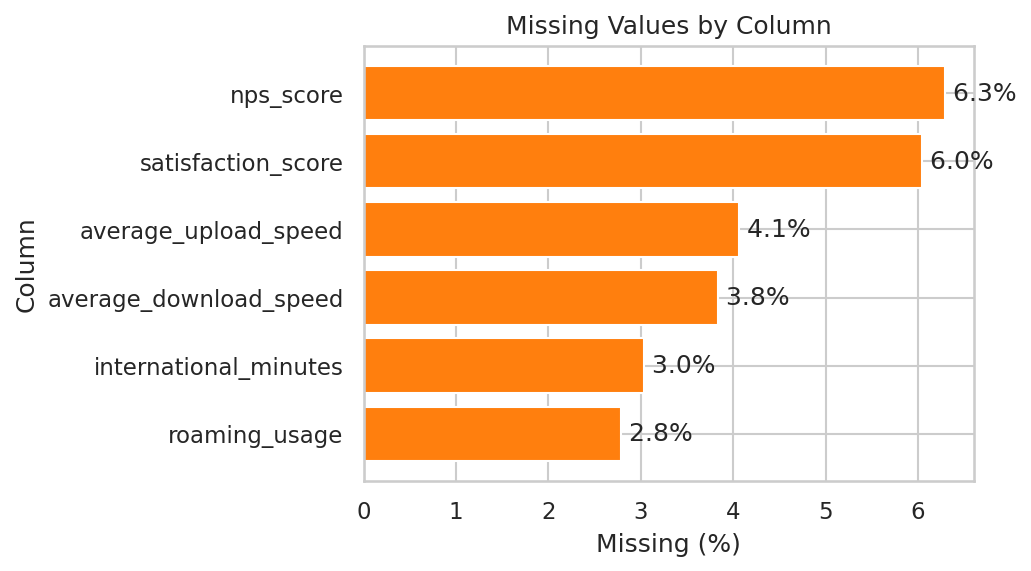

In [6]:
miss = df.isna().sum(); miss = miss[miss > 0]
display(pd.DataFrame({"missing": miss, "pct": (100 * miss / len(df)).round(2)}))
show("eda_11_missing_values.png", 600)

## 10. Exploratory Data Analysis

All plots are produced by `src/eda.py`. Below we show them with brief interpretation.

Saved EDA figures to /home/claude/telecom-churn-ai/outputs/figures


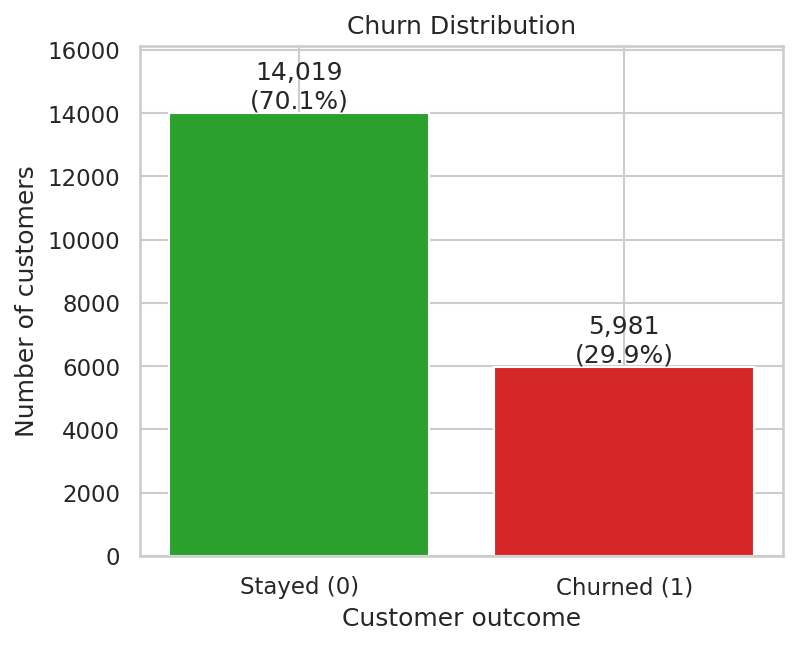

In [7]:
eda.make_all(df)
show("eda_01_churn_distribution.png", 450)

**Interpretation:** roughly 3 in 10 customers churn - an imbalanced (but not extreme) problem, so accuracy alone is misleading (see section 20).

## 11. Visualization

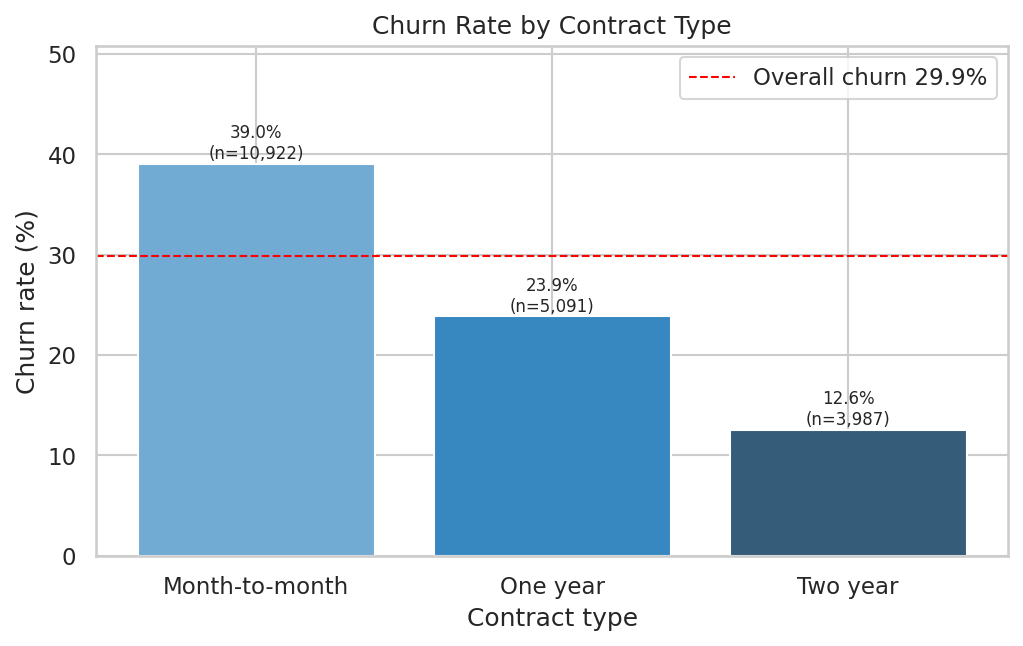

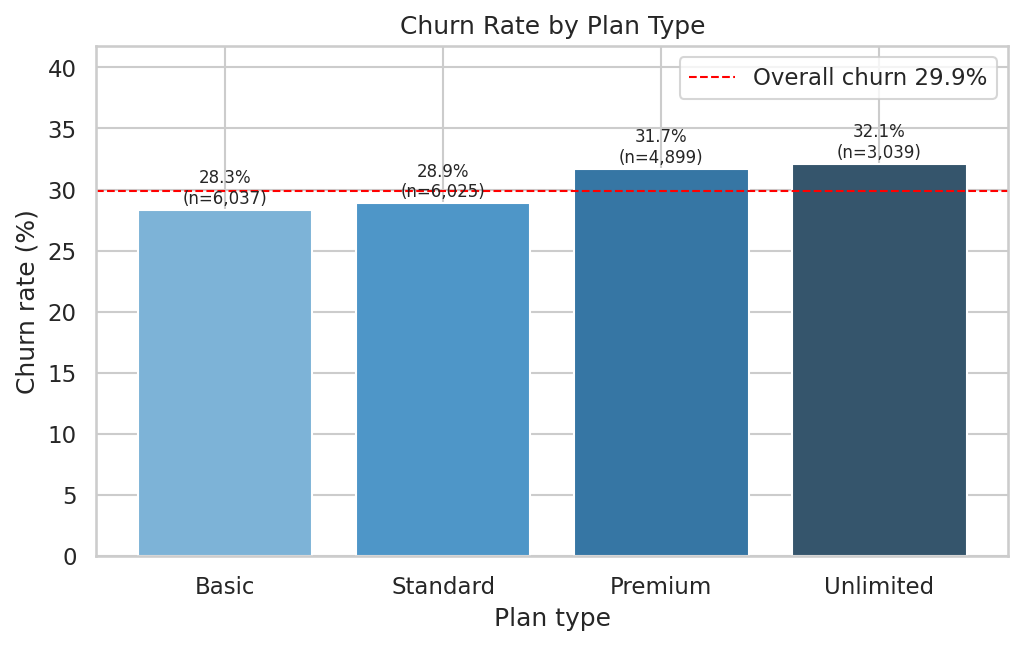

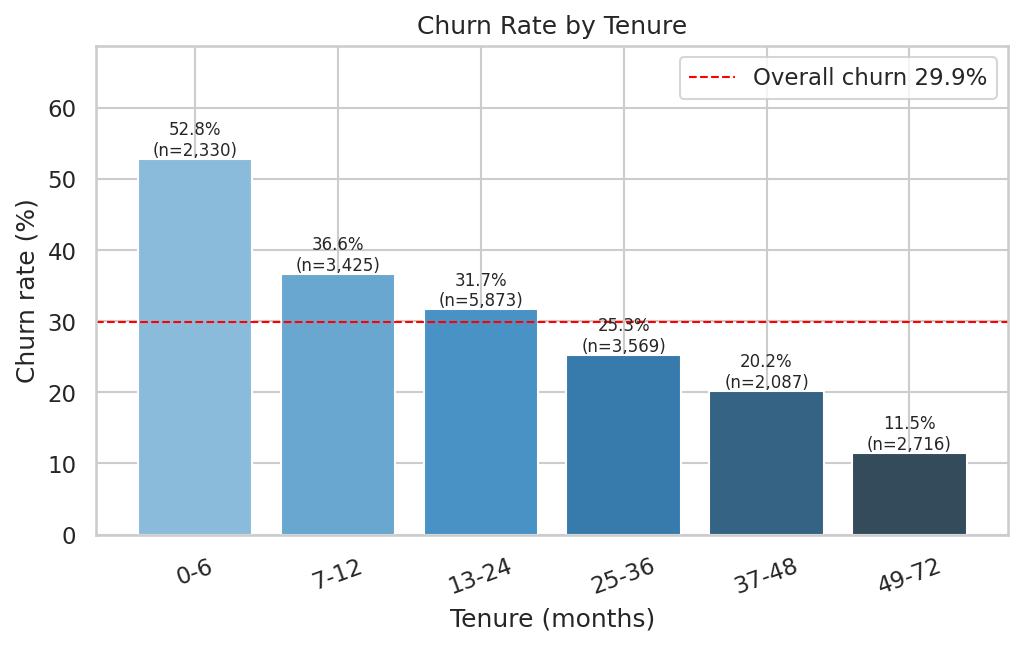

In [8]:
for f in ["eda_02_churn_by_contract.png", "eda_03_churn_by_plan.png", "eda_04_churn_by_tenure.png"]:
    show(f, 560)

**Interpretation:** churn falls steeply with longer contracts and longer tenure - new, month-to-month customers are the most exposed. Plan type has a smaller effect.

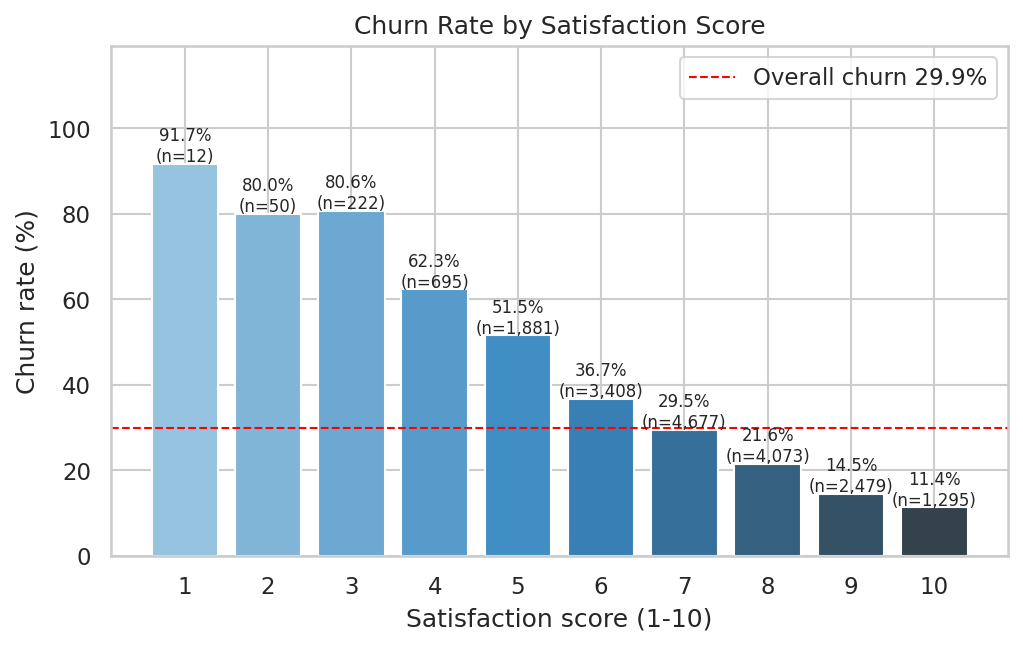

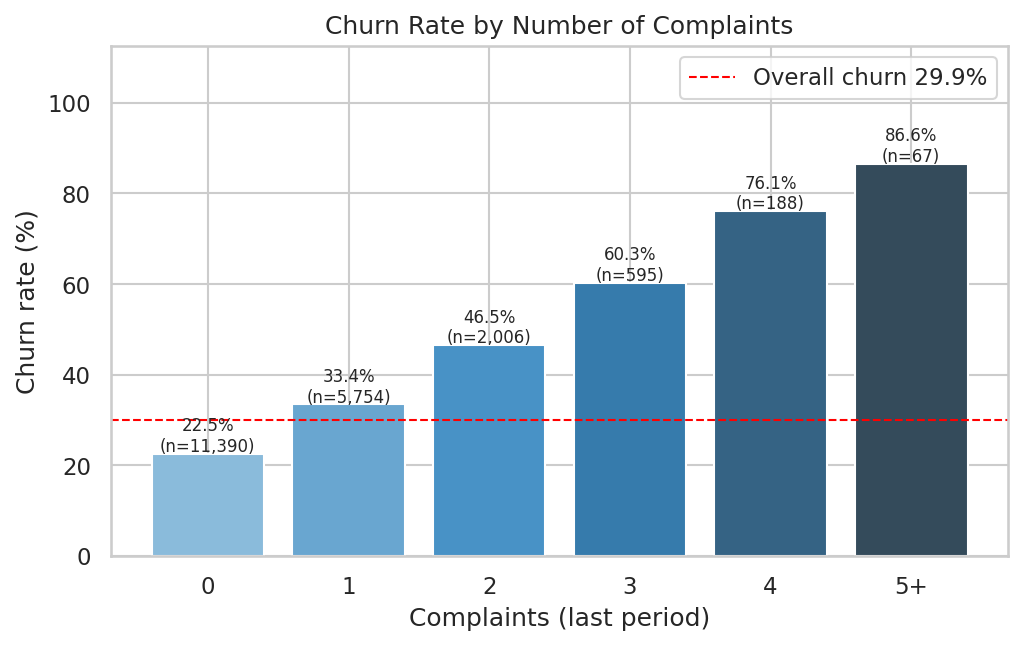

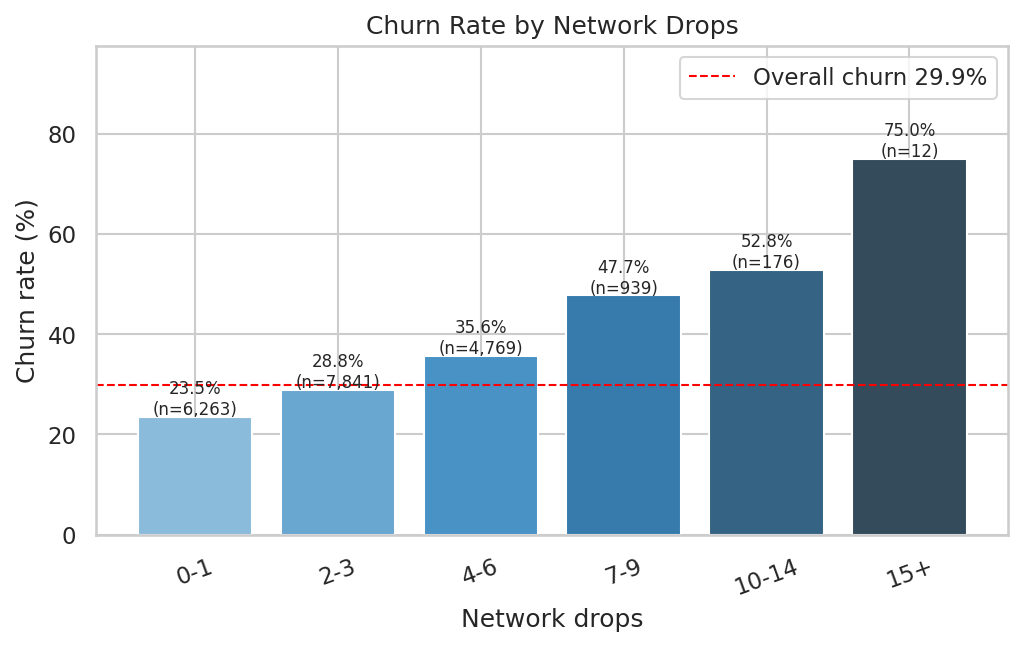

In [9]:
for f in ["eda_05_satisfaction_vs_churn.png", "eda_07_complaints_vs_churn.png", "eda_08_network_drops_vs_churn.png"]:
    show(f, 560)

**Interpretation:** churn rises as satisfaction falls and as complaints / network drops increase. These service-experience variables are actionable for the telecom operator.

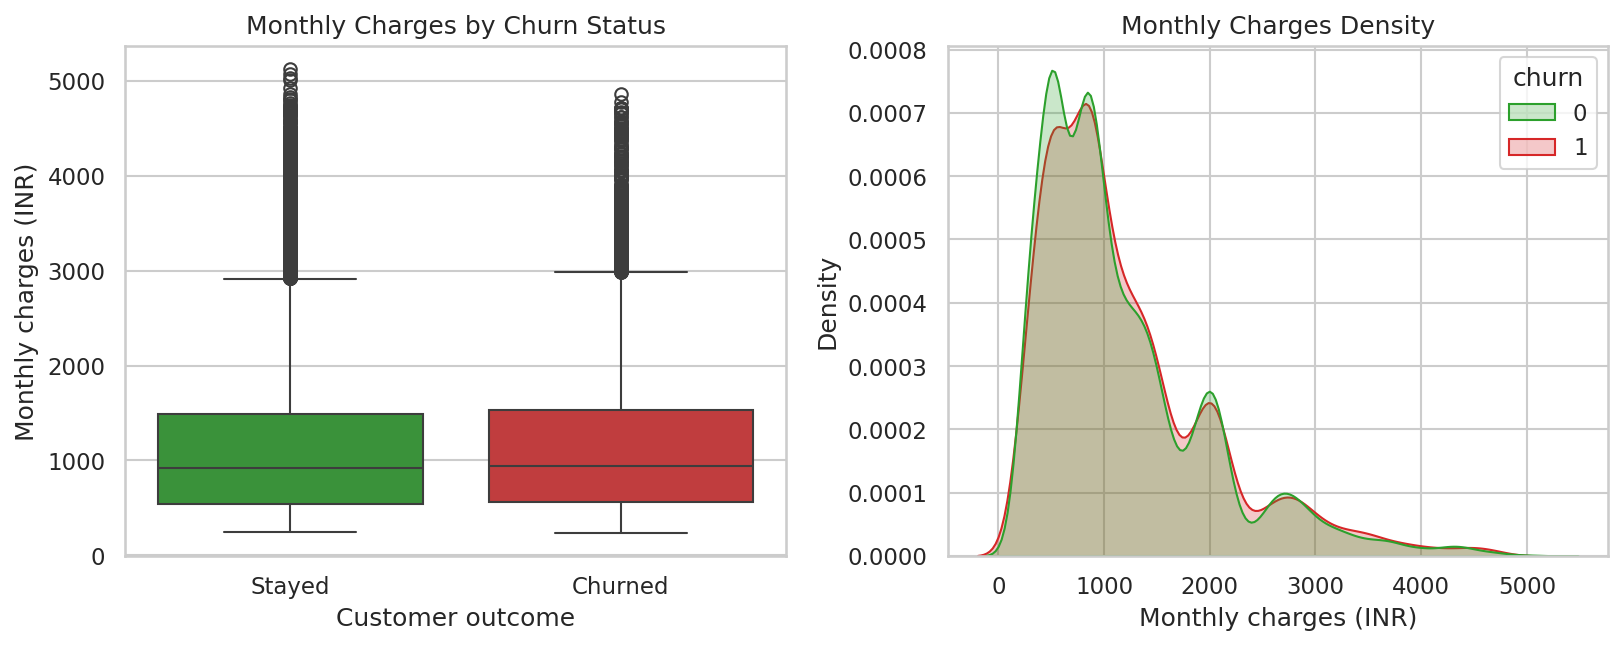

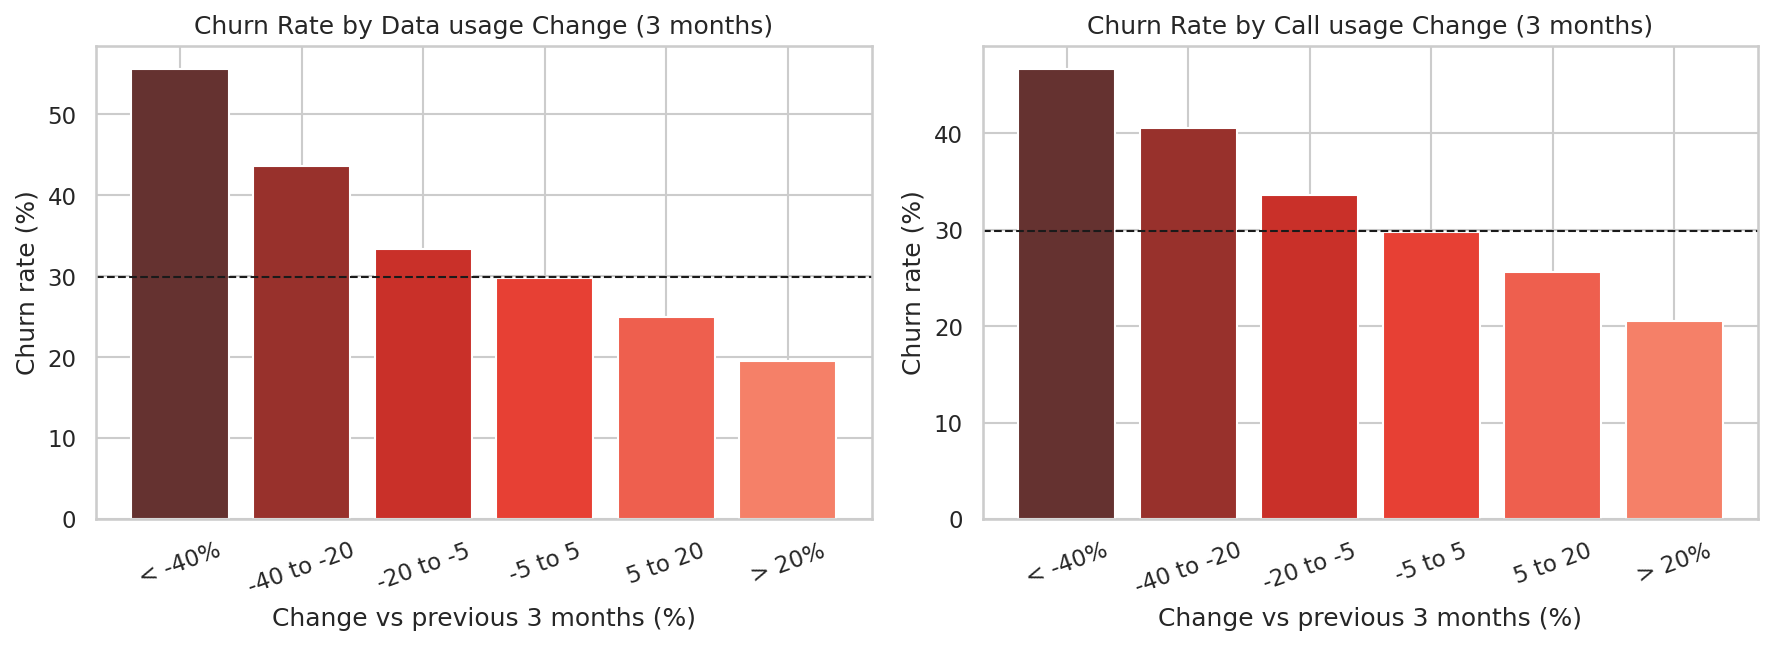

In [10]:
for f in ["eda_06_monthly_charges_vs_churn.png", "eda_09_usage_change_vs_churn.png"]:
    show(f, 800)

**Interpretation:** declining data/call usage over the last three months is a leading churn signal - a customer who is already disengaging. A static snapshot would miss this, which is why trend features are included.

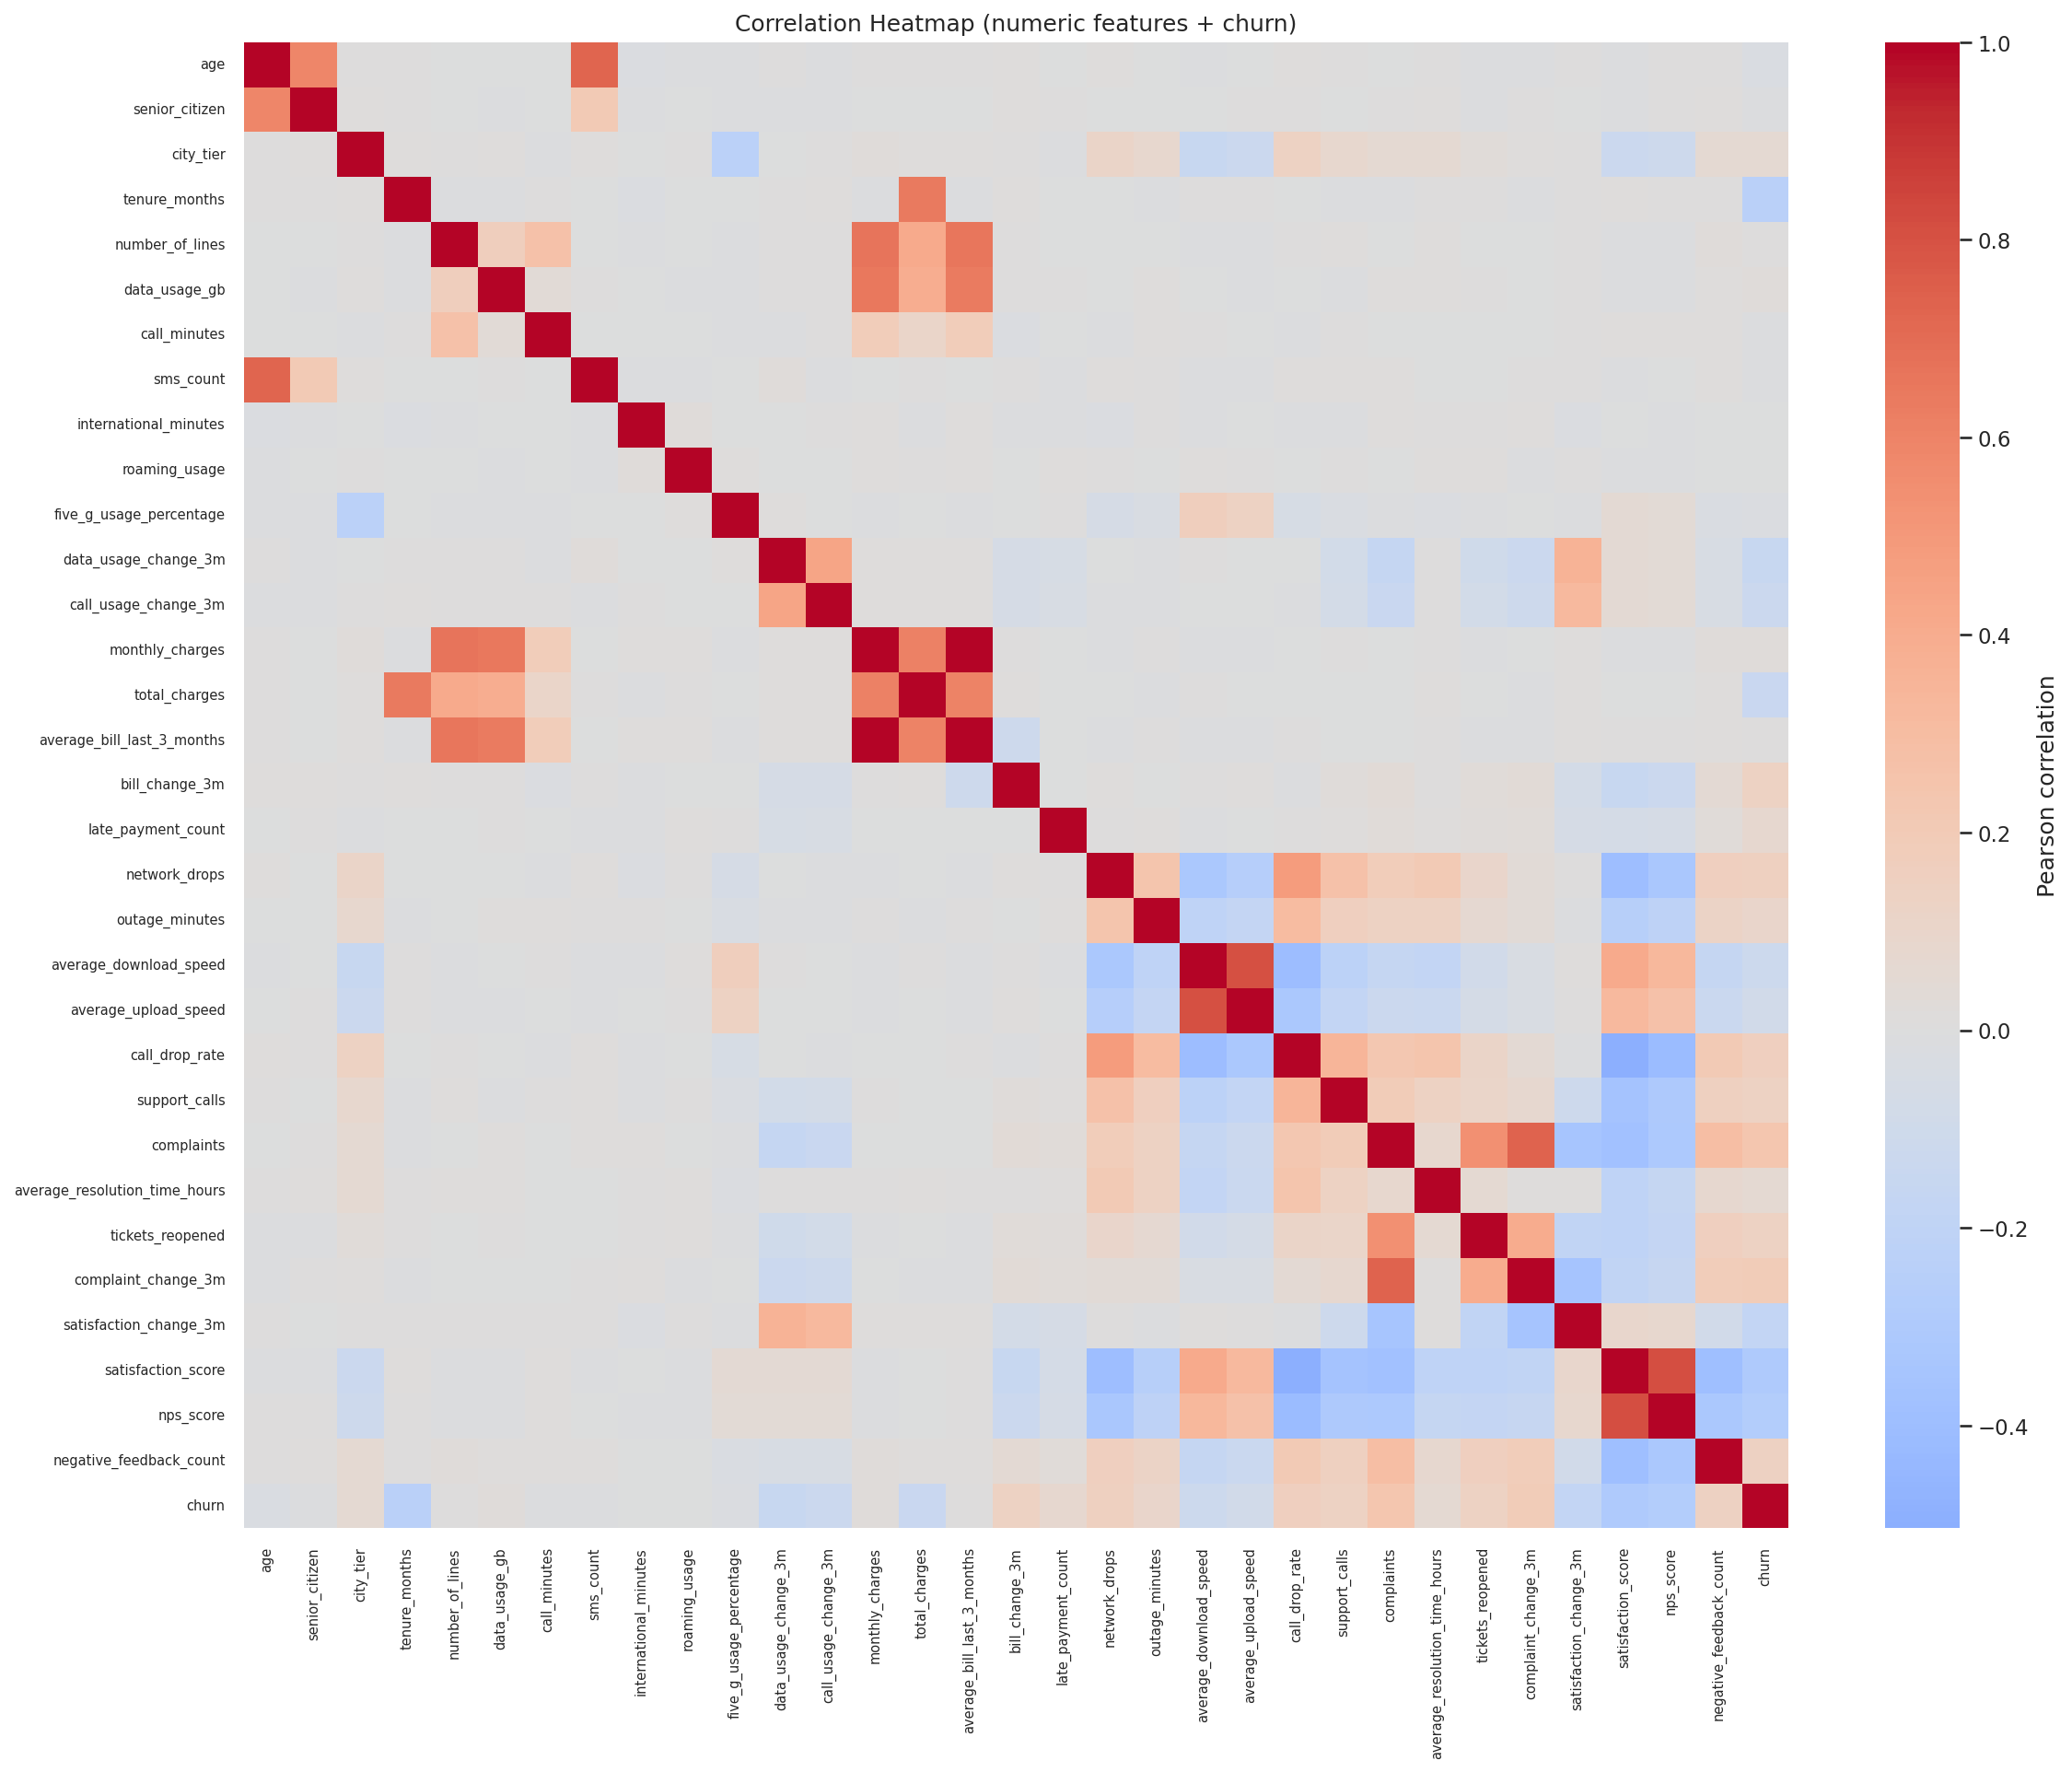

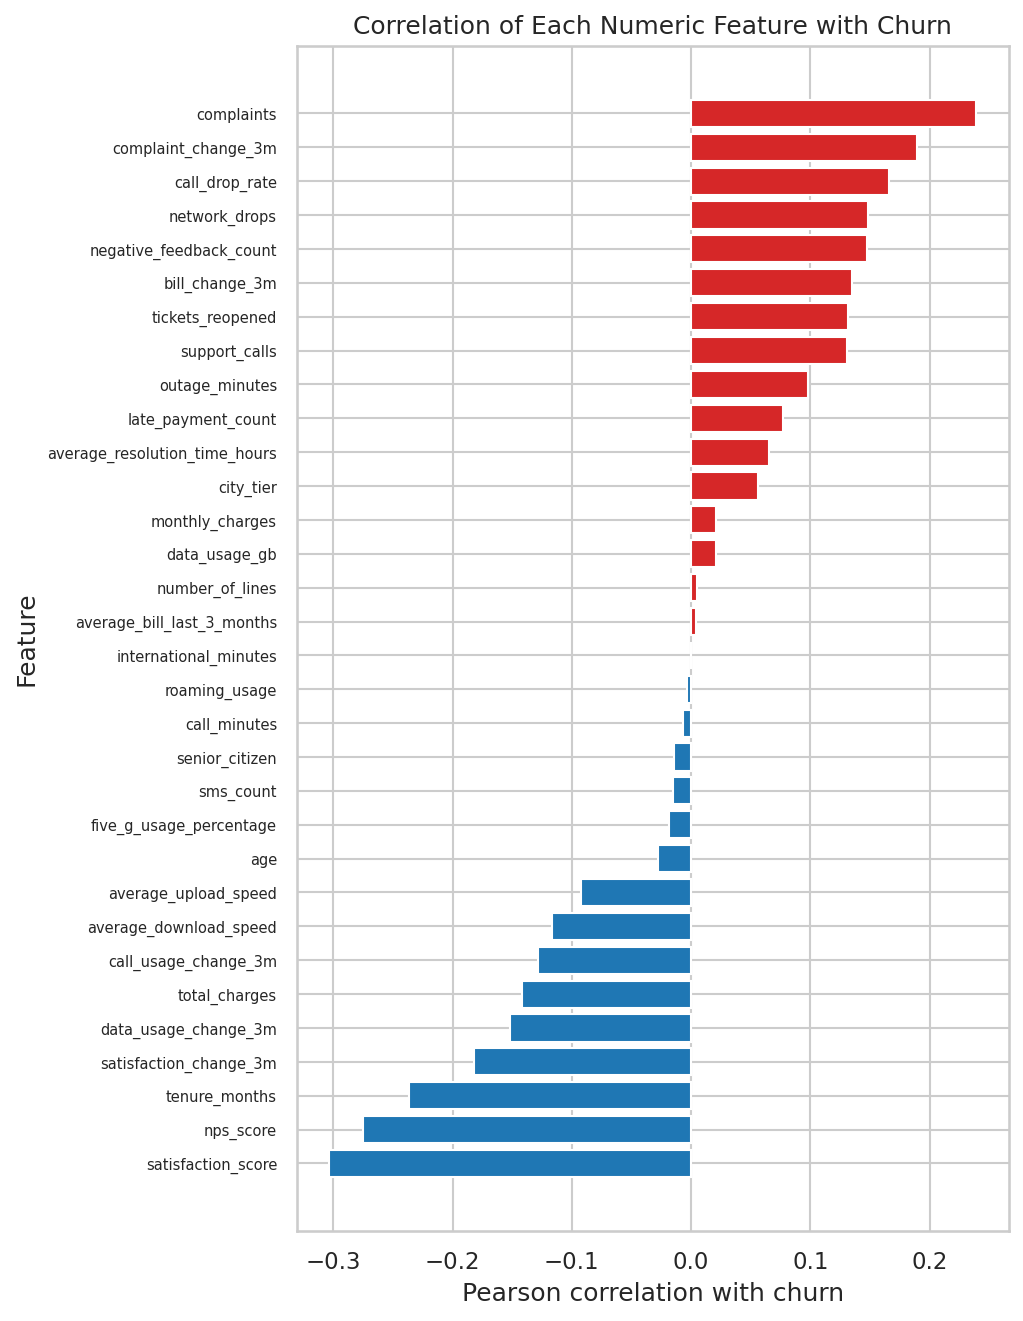

In [11]:
show("eda_10_correlation_heatmap.png", 900); show("eda_10b_correlation_with_churn.png", 520)

**Interpretation:** no single numeric feature is highly correlated with churn (no leakage), while several feature groups are correlated with each other (e.g. satisfaction vs NPS, network metrics vs complaints), which motivates regularised/ensemble models and a correlation filter.

## 12. Feature Engineering

Static attributes alone are not enough: *Customer A* (satisfaction 8, 1 complaint, stable usage) and *Customer B* (satisfaction fell 8 -> 4, complaints rising, usage declining, bill up)
may look similar in a snapshot but have very different risk. Beyond the five provided 3-month change features, we add fixed-formula features (no learned statistics, hence no leakage):
`spend_per_line`, `network_issue_index`, `support_intensity`, `is_new_customer`, `bill_shock`, and `n_negative_trends` (number of simultaneous deterioration signals).

In [12]:
dfe = prep.add_engineered_features(df)
dfe[prep.ENGINEERED].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
spend_per_line,20000.0,552.22,261.29,192.71,306.90,477.56,746.36,1301.86
network_issue_index,20000.0,1.78,1.01,0.09,1.07,1.57,2.25,9.46
support_intensity,20000.0,2.97,2.91,0.00,1.00,2.00,4.00,32.00
is_new_customer,20000.0,0.12,0.32,0.00,0.00,0.00,0.00,1.00
n_negative_trends,20000.0,1.04,1.09,0.00,0.00,1.00,2.00,5.00
bill_shock,20000.0,0.10,0.30,0.00,0.00,0.00,0.00,1.00


## 13. Feature Selection

Two safeguards, both computed on the **training split only**: (1) a **leakage audit** - single-feature ROC-AUC; any feature with AUC >= 0.90 (or a forbidden name such as cancellation/termination/retention-offer) would be flagged;
(2) a **correlation filter** dropping one feature of any pair with |r| > 0.95.

In [13]:
X_train, X_test, y_train, y_test = prep.get_split(dfe)
audit, bad = prep.leakage_audit(X_train, y_train)
print("Forbidden-name columns:", bad or "none", "| flagged features:", int(audit.leakage_flag.sum()))
display(audit.head(8).round(3))
numeric, categorical = prep.get_feature_lists(X_train)
numeric, dropped = prep.select_features(X_train, numeric)
print("Dropped by correlation filter:", dropped)
features = numeric + categorical; len(features)

Forbidden-name columns: none | flagged features: 0


,feature,single_feature_auc,strength,leakage_flag
0,satisfaction_score,0.327,0.673,False
1,nps_score,0.345,0.655,False
2,tenure_months,0.346,0.654,False
3,n_negative_trends,0.637,0.637,False
4,support_intensity,0.635,0.635,False
5,complaints,0.622,0.622,False
6,satisfaction_change_3m,0.392,0.608,False
7,total_charges,0.393,0.607,False


Dropped by correlation filter: ['average_bill_last_3_months']


42

**Interpretation:** the strongest single feature reaches only a modest AUC, confirming that no predictor leaks the target. Only the redundant `average_bill_last_3_months` (almost identical to `monthly_charges`) is removed.

## 14. Preprocessing

A `ColumnTransformer` handles numeric columns (median imputation + missing indicators [+ StandardScaler for the linear model]) and categorical columns
(most-frequent imputation + one-hot encoding with `handle_unknown='ignore'`). It sits **inside** each model `Pipeline`, so it is fitted only on training folds.
Tree models do not need scaling, so scaling is applied to Logistic Regression only.

In [14]:
pre = prep.build_preprocessor(numeric, categorical, scale=True)
pre.fit(X_train[features])
print("Transformed feature count:", len(pre.get_feature_names_out()))

Transformed feature count: 61


## 15. Train-Test Split

Stratified 80/20 split (`random_state=42`) keeps the 30% churn rate identical in both parts.
*Production note:* in a live telecom setting a **temporal split** (train on older months, test on the most recent month) is preferable because it mimics real deployment and exposes concept drift; a random split can be optimistic.

In [15]:
X_train, X_test = X_train[features], X_test[features]
print(X_train.shape, X_test.shape, "| churn:", round(y_train.mean(), 3), round(y_test.mean(), 3))

(16000, 42) (4000, 42) | churn: 0.299 0.299


## 16. Logistic Regression

Interpretable baseline: coefficients show direction and strength of every effect on the log-odds of churn.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
lr = Pipeline([("prep", prep.build_preprocessor(numeric, categorical, True)), ("clf", LogisticRegression(max_iter=3000, random_state=42))]).fit(X_train, y_train)
print("Quick test ROC-AUC:", round(ev.compute_metrics(y_test, lr.predict_proba(X_test)[:, 1])["roc_auc"], 4))

Quick test ROC-AUC: 0.7993


## 17. Random Forest

Captures non-linearities and interactions (untuned quick fit here; the tuned version is in section 19).

In [17]:
from sklearn.ensemble import RandomForestClassifier
rf = Pipeline([("prep", prep.build_preprocessor(numeric, categorical, False)), ("clf", RandomForestClassifier(n_estimators=150, max_depth=8, min_samples_leaf=20, random_state=42, n_jobs=-1))]).fit(X_train, y_train)
print("Quick test ROC-AUC:", round(ev.compute_metrics(y_test, rf.predict_proba(X_test)[:, 1])["roc_auc"], 4))

Quick test ROC-AUC: 0.7895


## 18. XGBoost

Gradient-boosted trees - the advanced model (untuned quick fit here).

In [18]:
from xgboost import XGBClassifier
xgb = Pipeline([("prep", prep.build_preprocessor(numeric, categorical, False)), ("clf", XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42, eval_metric="logloss", n_jobs=1))]).fit(X_train, y_train)
print("Quick test ROC-AUC:", round(ev.compute_metrics(y_test, xgb.predict_proba(X_test)[:, 1])["roc_auc"], 4))

Quick test ROC-AUC: 0.7971


## 19. Hyperparameter Tuning

`RandomizedSearchCV` on the **training set only** (3-fold stratified CV, scoring = ROC-AUC) for Random Forest (`n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`)
and XGBoost (`n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`, `min_child_weight`). The search was run by `train_models.py`; results are loaded here.

In [19]:
print(open(MET / "best_params.json").read())
display(pd.read_csv(MET / "tuning_xgboost.csv").head(5).filter(regex="param_|mean_test|std_test|rank").round(4))

{
  "Random Forest": {
    "n_estimators": 100,
    "min_samples_leaf": 40,
    "max_features": "sqrt",
    "max_depth": 14
  },
  "XGBoost": {
    "subsample": 0.85,
    "n_estimators": 500,
    "min_child_weight": 5,
    "max_depth": 4,
    "learning_rate": 0.02,
    "colsample_bytree": 0.6
  }
}


,param_clf__subsample,param_clf__n_estimators,param_clf__min_child_weight,param_clf__max_depth,param_clf__learning_rate,param_clf__colsample_bytree,mean_test_score,std_test_score,rank_test_score
0,0.85,500,5,4,0.02,0.6,0.7954,0.0062,1
1,0.85,200,10,3,0.05,0.8,0.7954,0.0068,2
2,0.70,300,5,4,0.02,1.0,0.7951,0.0073,3
3,1.00,200,5,2,0.05,1.0,0.7951,0.0070,4
4,0.70,300,1,2,0.10,1.0,0.7945,0.0071,5


## 20. Model Evaluation

**Why accuracy is not enough.** If 90% of customers stay, predicting "stay" for everyone gives 90% accuracy yet catches zero churners. Even at 30% churn, accuracy hides the trade-off between
**precision** (of the customers we flag, how many really churn - wasted offers) and **recall** (of the real churners, how many we catch - lost revenue). **F1** balances them; **ROC-AUC** measures ranking quality across all thresholds;
**PR-AUC** is more informative when the positive class is rare. Because missing a churner is usually costlier than a wasted offer, we give recall special attention.

In [20]:
cfg = json.load(open(ROOT / "models" / "model_config.json"))
models = {n: joblib.load(ROOT / "models" / f"{f}.pkl") for n, f in [("Logistic Regression", "logistic_regression"), ("Random Forest", "random_forest"), ("XGBoost", "xgboost")]}
probas = {n: m.predict_proba(X_test[cfg["features"]])[:, 1] for n, m in models.items()}
table = pd.DataFrame({n: ev.compute_metrics(y_test, p) for n, p in probas.items()}).T
display(table.round(4))

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,brier
Logistic Regression,0.5,0.7700,0.6760,0.4431,0.5354,0.7993,0.6516,0.1574
Random Forest,0.5,0.7632,0.7310,0.3294,0.4542,0.7896,0.6364,0.1638
XGBoost,0.5,0.7720,0.6835,0.4423,0.5371,0.7979,0.6493,0.1580


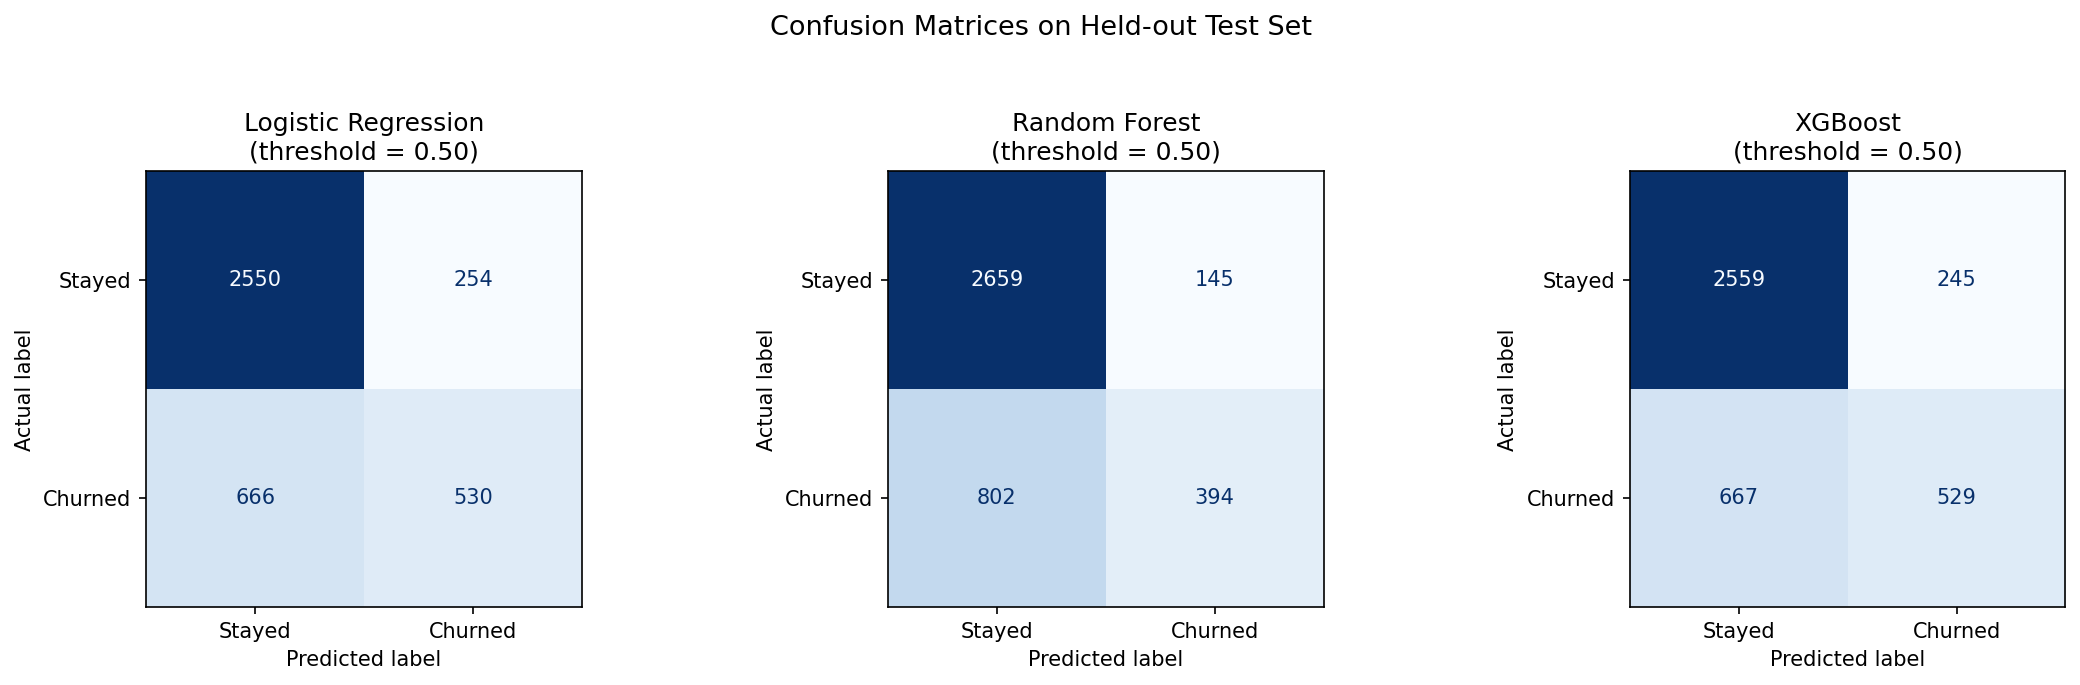

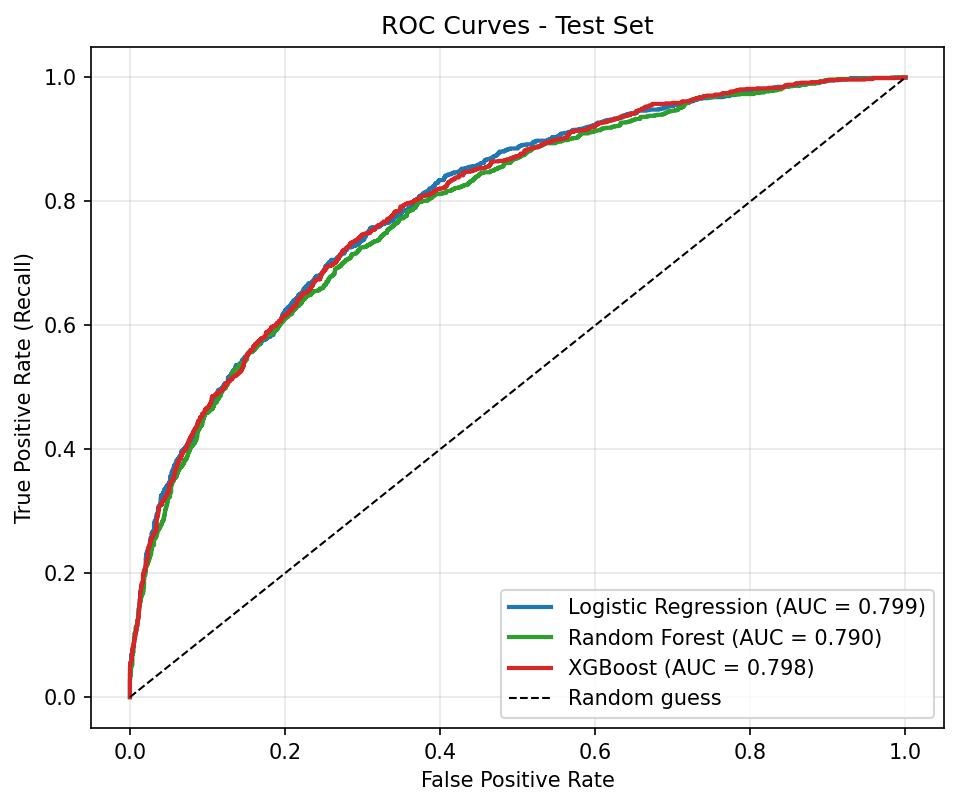

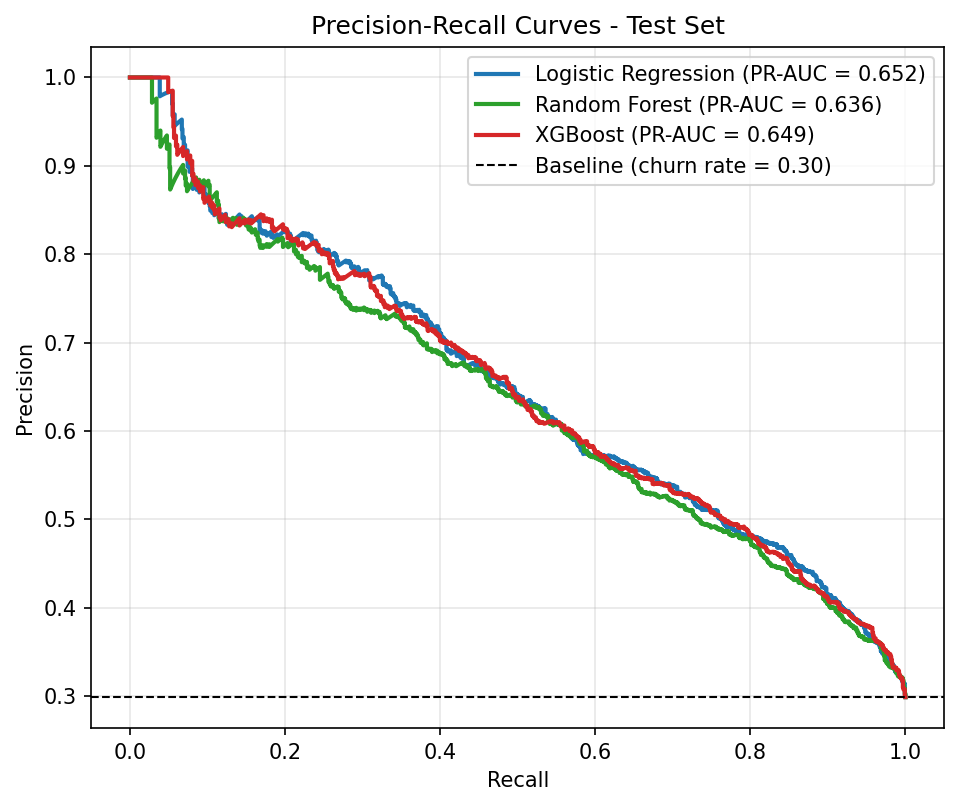

In [21]:
show("confusion_matrices.png", 1000); show("roc_curves.png", 520); show("precision_recall_curves.png", 520)

**Interpretation:** the confusion matrices at the default 0.5 threshold show high precision but modest recall - many churners are missed. Section 25 shows how a business-driven threshold changes this.

## 21. Model Comparison

The best model is selected using **cross-validated ROC-AUC on the training data**, not the test score, to avoid selecting on the test set.

,cv_roc_auc_train,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,brier
model,,,,,,,,,
Logistic Regression,0.8001,0.5,0.7700,0.6760,0.4431,0.5354,0.7993,0.6516,0.1574
Random Forest,0.7880,0.5,0.7632,0.7310,0.3294,0.4542,0.7896,0.6364,0.1638
XGBoost,0.7966,0.5,0.7720,0.6835,0.4423,0.5371,0.7979,0.6493,0.1580


Selected best model: Logistic Regression | CV AUC: {'Logistic Regression': 0.8001, 'Random Forest': 0.788, 'XGBoost': 0.7966}


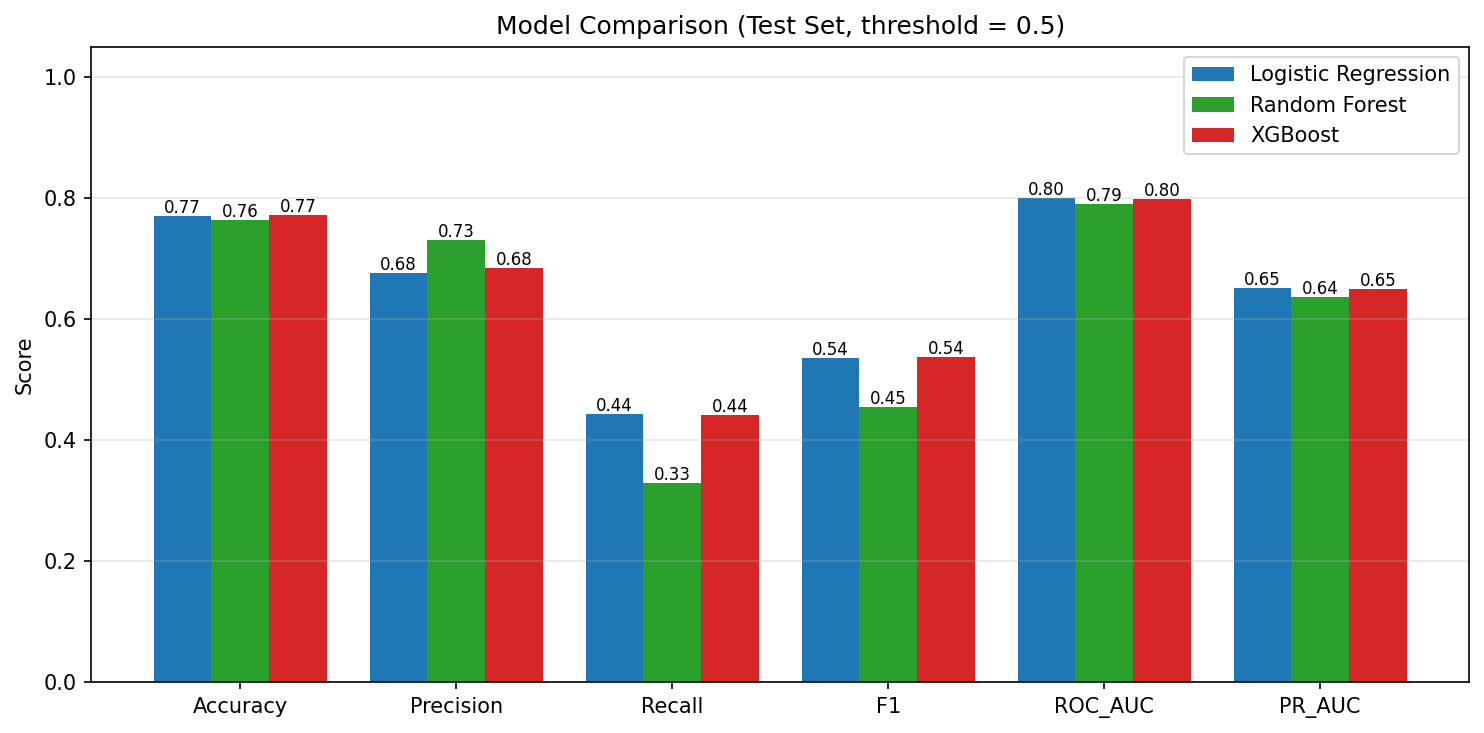

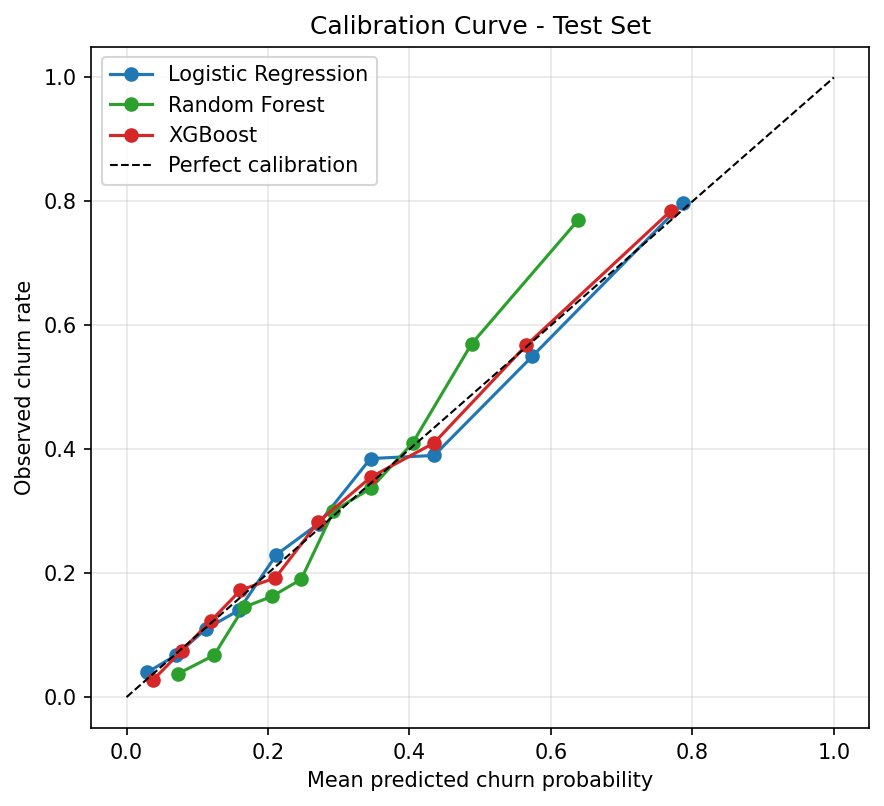

In [22]:
display(pd.read_csv(MET / "model_comparison.csv", index_col=0).round(4))
print("Selected best model:", cfg["best_model"], "| CV AUC:", {k: round(v, 4) for k, v in cfg["cv_roc_auc"].items()})
show("model_comparison.png", 800); show("calibration_curve.png", 480)

**Interpretation:** the three models score very close to one another. The data contain mostly additive effects with a few interactions, so a well-regularised linear model is highly competitive - an honest finding, not a flaw. Calibration matters because probabilities are mapped to risk levels.

## 22. Feature Importance

Global importance = mean absolute SHAP value of the best model, aggregated from one-hot columns back to the original feature.

contract_type                ######################################## 0.455
tenure_months                ############################### 0.359
satisfaction_score           ########################## 0.302
data_usage_change_3m         ############## 0.166
satisfaction_change_3m       ############## 0.166
nps_score                    ############# 0.154
bill_change_3m               ############ 0.145
payment_method               ########### 0.134
is_new_customer              ########### 0.130
complaint_change_3m          ########## 0.125
late_payment_count           ####### 0.086
call_usage_change_3m         ####### 0.083


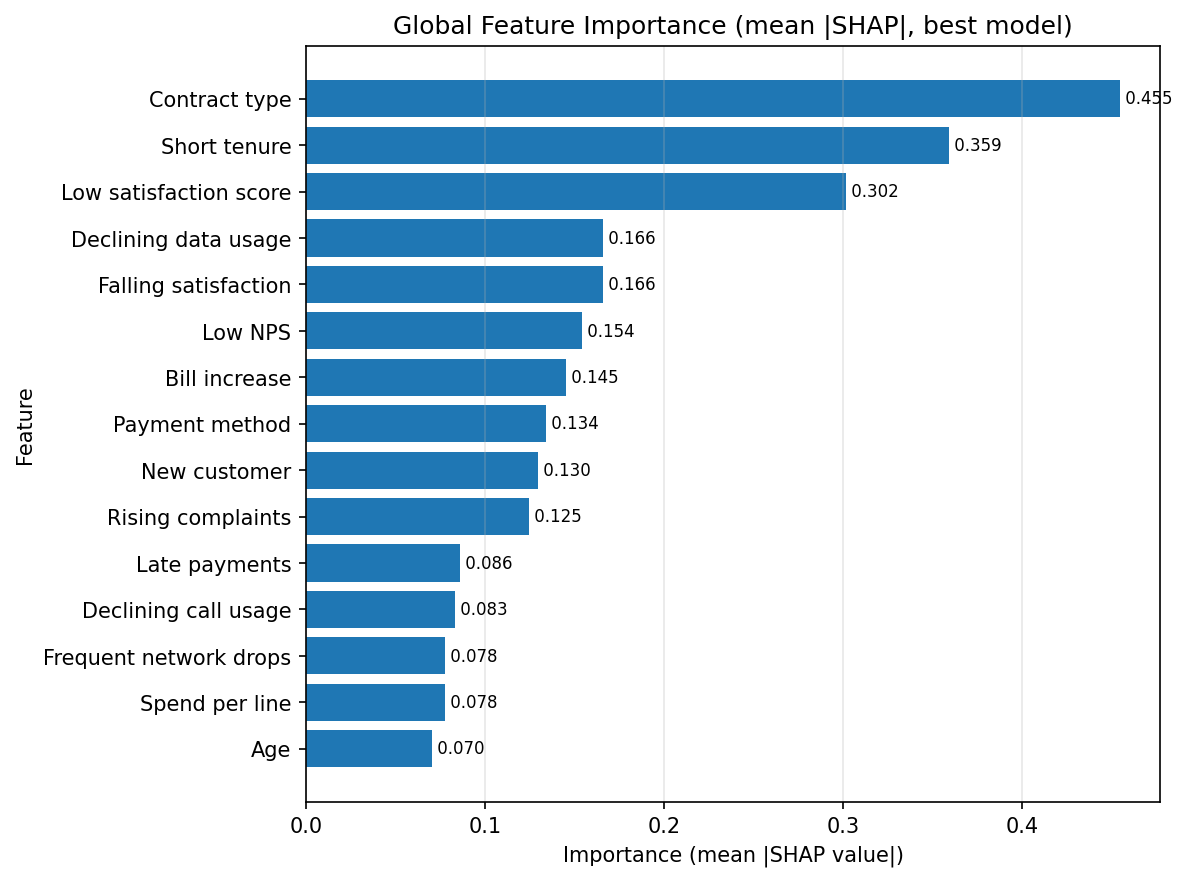

In [23]:
imp = pd.read_csv(MET / "feature_importance.csv", index_col=0).iloc[:, 0]
for f, v in imp.head(12).items():
    print(f"{f:28s} {'#' * int(40 * v / imp.iloc[0])} {v:.3f}")
show("feature_importance.png", 650)

## 23. SHAP Explainability

SHAP assigns each feature a contribution to a customer's churn log-odds. The summary plot shows the global picture (colour = feature value, position = push towards churn);
the individual plot explains one customer. The explanations are computed from the trained model - nothing is hand-written.

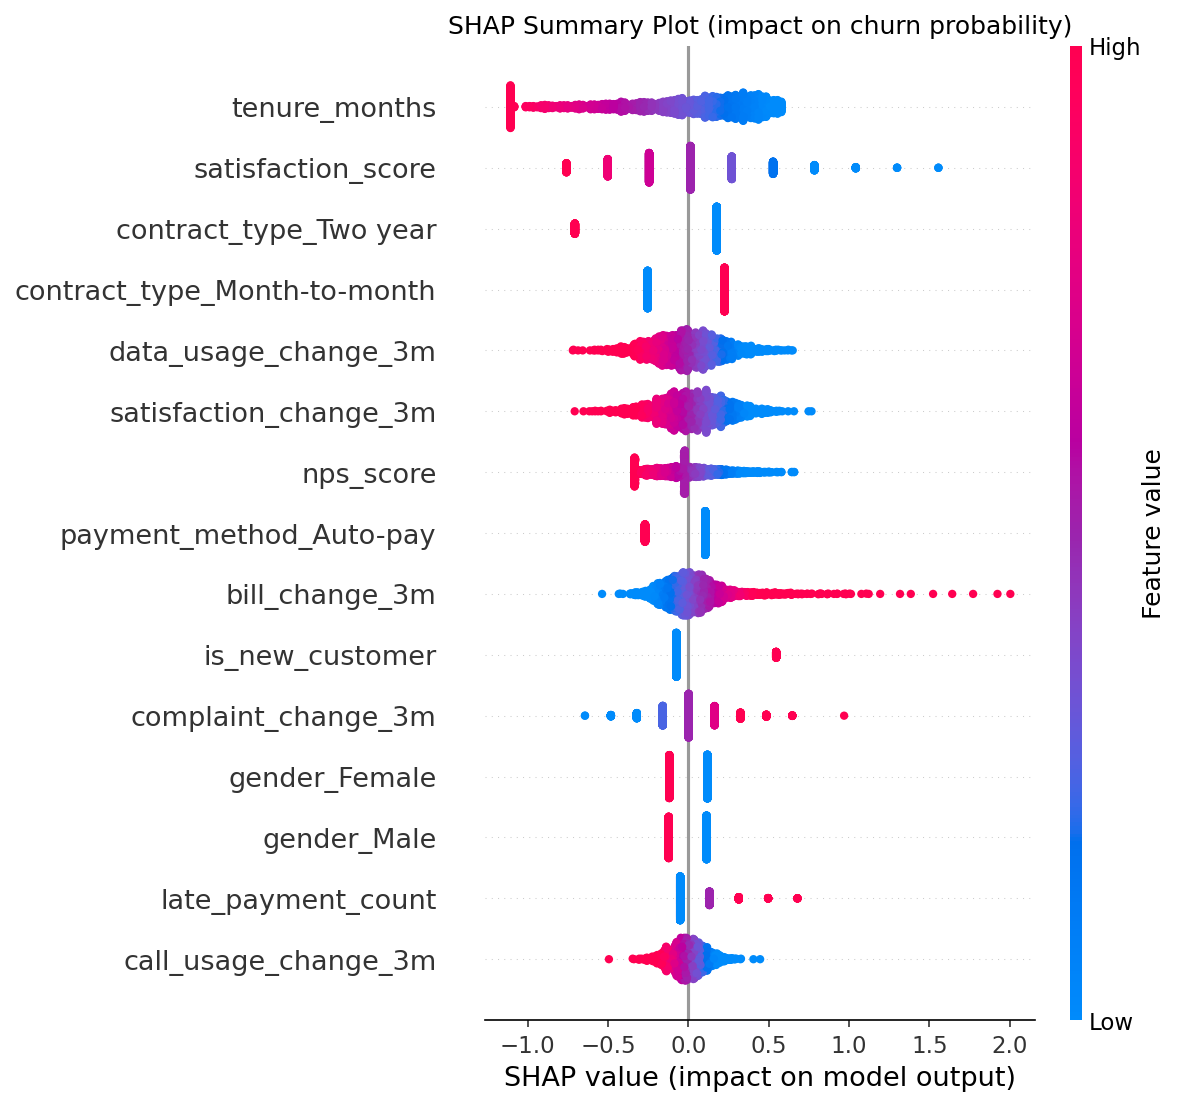

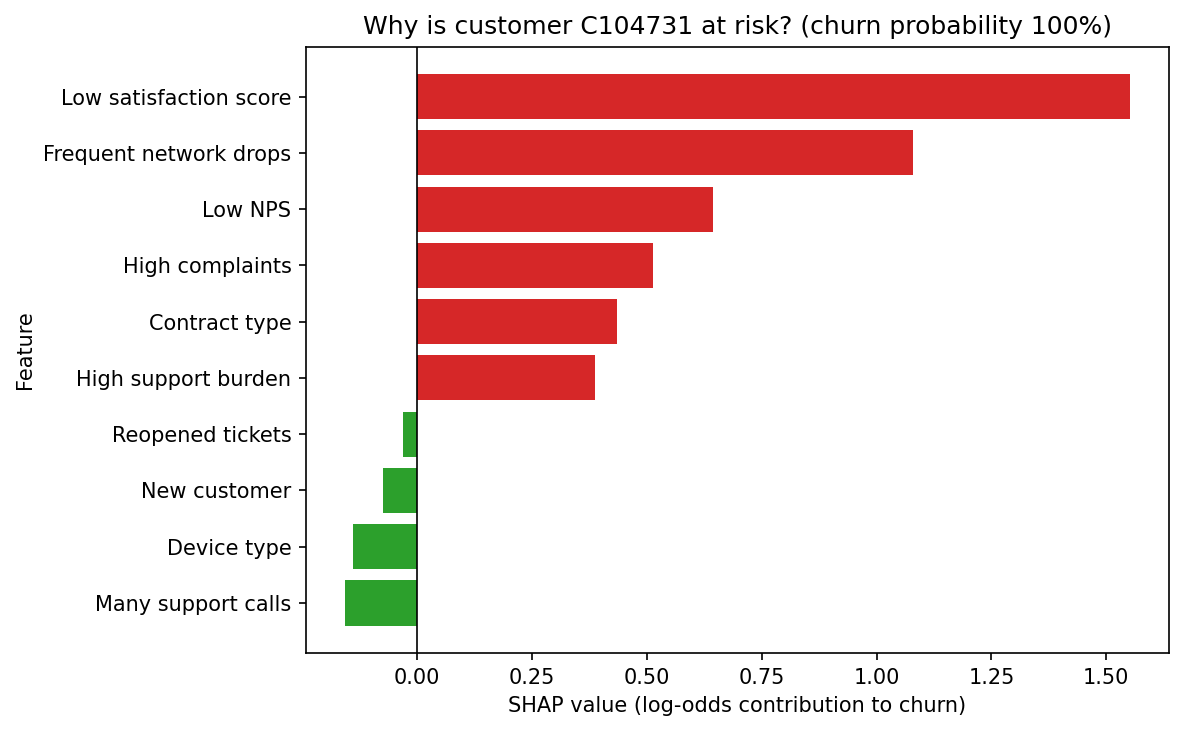

Customer C104731 - churn probability 100%
Main contributing factors:
  1. Low satisfaction score (value: 1.0, SHAP +1.55)
  2. Frequent network drops (value: 26, SHAP +1.08)
  3. Low NPS (value: -97.0, SHAP +0.64)
  4. High complaints (value: 6, SHAP +0.51)
  5. Contract type (value: Month-to-month, SHAP +0.43)


In [24]:
show("shap_summary.png", 750); show("shap_individual_example.png", 650)
ex = json.load(open(MET / "shap_individual_example.json"))
print(f"Customer {ex['customer_id']} - churn probability {ex['churn_probability']:.0%}\nMain contributing factors:")
for i, f in enumerate(ex["risk_factors"], 1): print(f"  {i}. {f['label']} (value: {f['value']}, SHAP {f['shap']:+.2f})")

## 24. Churn Probability

Final output per customer: `customer_id`, `churn_probability`, `risk_level` (plus factors and action). Produced by `python src/predict.py`.
Note: customers in the *training* split are in-sample; use rows with `split == "test"` for honest evaluation.

In [25]:
pred = pd.read_csv(ROOT / "outputs" / "predictions" / "churn_predictions.csv")
display(pred.sort_values("churn_probability", ascending=False).head(5)[["customer_id", "churn_probability", "risk_level", "customer_health_score", "top_risk_factors"]])

,customer_id,churn_probability,risk_level,customer_health_score,top_risk_factors
5231,C105231,0.9968,CRITICAL,26.4,Low satisfaction score (2.0); Rising complaint...
4731,C104731,0.9963,CRITICAL,20.2,Low satisfaction score (1.0); Frequent network...
4646,C104646,0.9950,CRITICAL,32.3,Low satisfaction score (2.0); Rising complaint...
11209,C111209,0.9945,CRITICAL,30.4,Rising complaints (11); Low satisfaction score...
1633,C101633,0.9940,CRITICAL,34.8,Rising complaints (7); Low satisfaction score ...


## 25. Customer Risk Segmentation

Business thresholds (adjustable in `retention.py`): **0-30% LOW, 30-60% MEDIUM, 60-80% HIGH, 80-100% CRITICAL**.

,customers,avg_prob,actual_churn_rate
risk_level,,,
LOW,2379,0.141,0.143
MEDIUM,1083,0.425,0.416
HIGH,377,0.693,0.714
CRITICAL,161,0.875,0.851


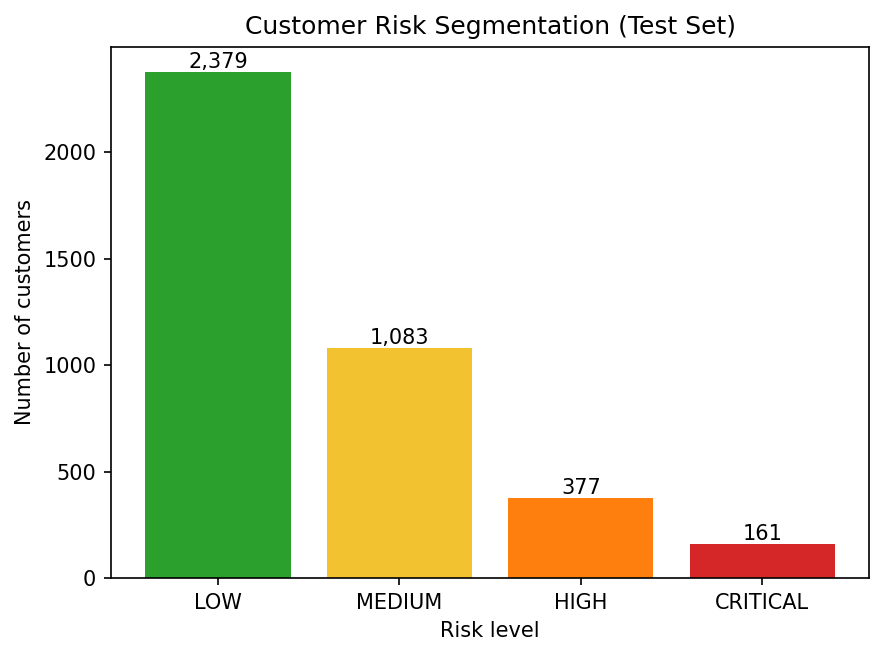

Operating threshold giving >= 70% recall (chosen on training OOF): 0.31


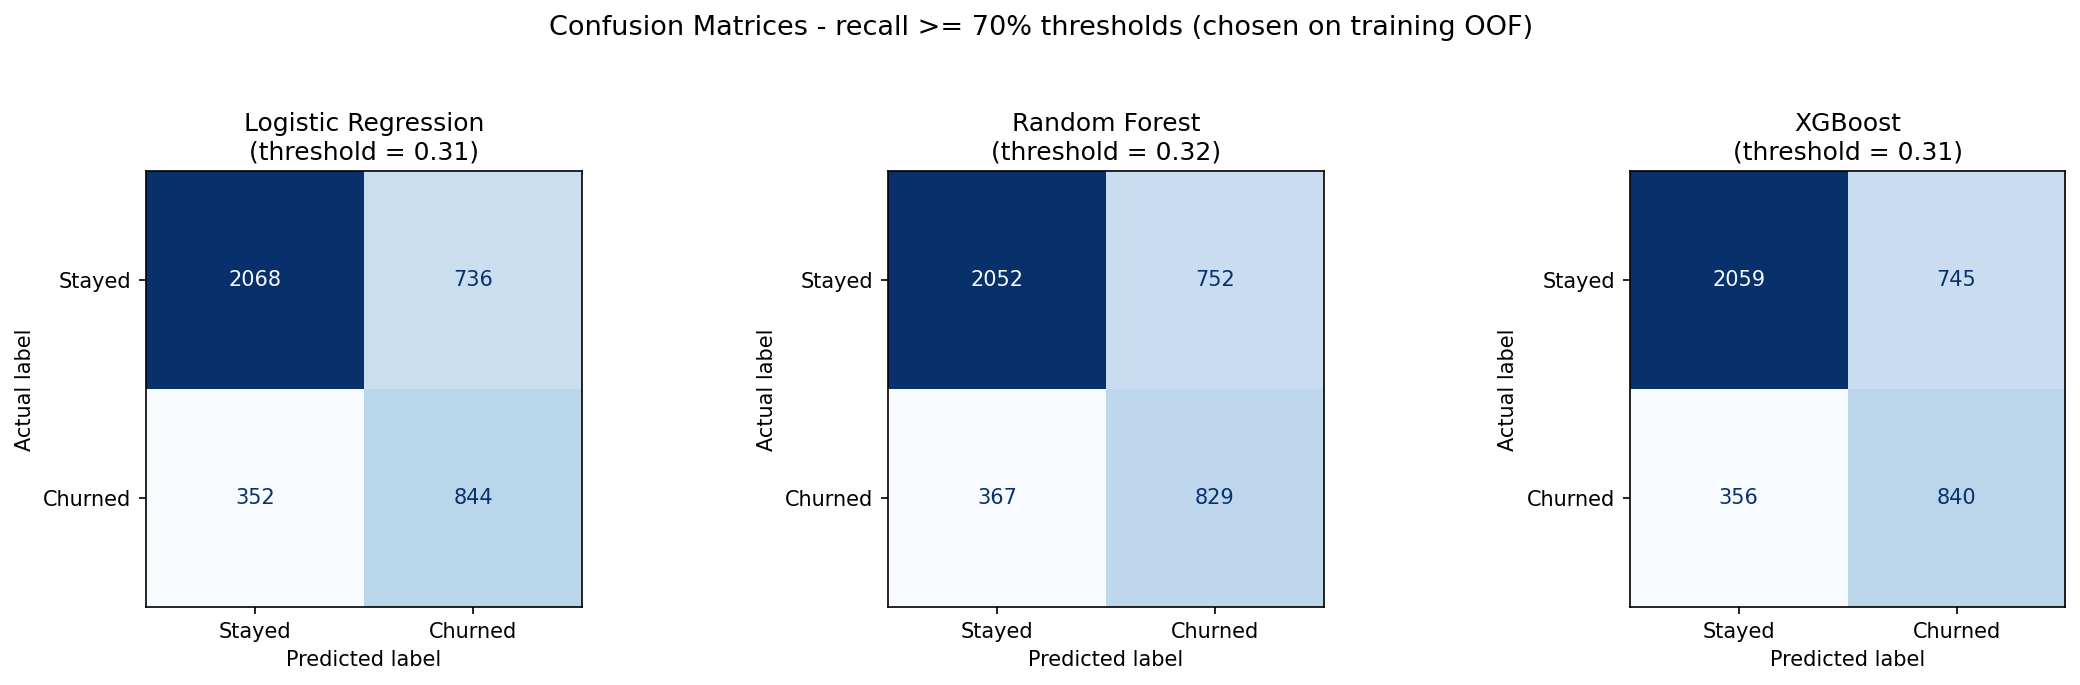

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,brier
model,,,,,,,,
Logistic Regression,0.31,0.7280,0.5342,0.7057,0.6081,0.7993,0.6516,0.1574
Random Forest,0.32,0.7202,0.5244,0.6931,0.5970,0.7896,0.6364,0.1638
XGBoost,0.31,0.7248,0.5300,0.7023,0.6041,0.7979,0.6493,0.1580


In [26]:
t = pred[pred.split == "test"]
seg = t.groupby("risk_level").agg(customers=("customer_id", "size"), avg_prob=("churn_probability", "mean"), actual_churn_rate=("actual_churn", "mean")).reindex(["LOW", "MEDIUM", "HIGH", "CRITICAL"])
display(seg.round(3)); show("risk_level_distribution.png", 450)
print("Operating threshold giving >= 70% recall (chosen on training OOF):", cfg["decision_threshold"])
show("confusion_matrices_tuned_threshold.png", 1000)
display(pd.read_csv(MET / "model_comparison_tuned_threshold.csv", index_col=0).round(4))

**Interpretation:** the observed churn rate rises monotonically across the risk levels, which shows the probabilities are meaningful, not just rankings. Lowering the decision threshold trades precision for recall - the right point depends on the cost of a retention offer versus a lost customer.

## 26. Retention Recommendation

The retention layer in `retention.py` is **rule-based** (e.g. many network problems -> network investigation; bill rise + high spend -> loyalty plan; low satisfaction + many support calls -> priority service;
late payments -> flexible payment). The ML model supplies only the probability and the SHAP factors used to *prioritise* the rules - it does not generate the action text. We also compute a
**customer_health_score** (0-100): a weighted, fixed-bound business index of satisfaction, network quality, complaint burden, payment stability and engagement trend (never uses the churn label).

In [27]:
display(pred[pred.risk_level.isin(["HIGH", "CRITICAL"])].head(5)[["customer_id", "churn_probability", "risk_level", "top_risk_factors", "recommended_action"]])
print(pred.groupby("risk_level")["customer_health_score"].mean().round(1))

,customer_id,churn_probability,risk_level,top_risk_factors,recommended_action
0,C100000,0.6917,HIGH,Low satisfaction score (4.0); Contract type (M...,Priority customer-service intervention: senior...
14,C100014,0.7446,HIGH,Short tenure (2); New customer (1); Contract t...,Offer a discounted 12-month contract upgrade w...
24,C100024,0.6447,HIGH,Bill increase (34.6); Contract type (Month-to-...,Run a re-engagement campaign: personalised dat...
43,C100043,0.7630,HIGH,Short tenure (2); New customer (1); Contract t...,Offer a discounted 12-month contract upgrade w...
46,C100046,0.7627,HIGH,Low satisfaction score (4.0); Contract type (M...,Priority customer-service intervention: senior...


risk_level
CRITICAL    57.2
HIGH        66.1
LOW         79.7
MEDIUM      72.2
Name: customer_health_score, dtype: float64


## 27. Business Interpretation

* Churn probability lets the retention team focus a limited budget on the customers where it matters most (rank by probability x customer value).
* SHAP factors tell agents *what to talk about* with each customer; aggregated factors show systemic issues (e.g. a network problem in an area).
* Actionable drivers (satisfaction, complaints, bill shock, network quality) point to operational fixes - not just marketing offers.
* Month-to-month, short-tenure customers are structurally riskier: converting them to longer contracts is a strategic lever.

## 28. Conclusion

We built a leakage-free, reproducible pipeline that predicts churn, explains it, and links it to retention actions. Model performance on this synthetic dataset is moderate and realistic (see metrics above) and the three
models are close, which is a credible outcome because the generator contains irreducible noise. The system answers WHO, WHY and WHAT.

## 29. Future Scope

* **Uplift / treatment-effect modelling**: ordinary churn prediction answers *who is likely to churn*; an advanced system should answer *who is likely to churn AND can be saved by an intervention*.
  A customer with 90% churn risk who will leave regardless is a worse target than a 70%-risk customer who responds strongly to an offer.
* Temporal / sequence models on monthly histories, real-time scoring, customer-lifetime-value weighting, causal inference, personalised offers, CRM integration, validation on real telecom data, fairness testing and drift monitoring.